# Problem Definition

The objective of this project is to build a machine learning model capable of predicting the selling price of used cars based on vehicle characteristics such as brand, model, year, transmission, fuel type, mileage, ownership history, and other listing features.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


#### Load Dataset

The dataset file (used_cars_dataset.csv) should be placed in the same directory as this notebook before running the code.

In [2]:
df = pd.read_csv("used_cars_dataset.csv")

df_original = df.copy()

### Dataset Exploration


In [3]:
df.head()

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
0,NaN,NaN,2001.0,23.0,"98,000 km",NaN,NaN,Unknown,Nov-24,"Honda City v teck in mint condition, valid gen...","₹ 1,95,000"
1,Toyota,NaN,NaN,15.0,190000.0 km,Manual,NaN,Diesel,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...","₹ 3,75,000"
2,Volkswagen,NaN,2010.0,NaN,NaN,Manual,first,NaN,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...","₹ 1,84,999"
3,NaN,Swift,2017.0,7.0,NaN,Manual,second,Unknown,NaN,Maruti Suzuki Swift 2017 Diesel Good Condition,"₹ 5,65,000"
4,Maruti Suzuki,NaN,2019.0,5.0,NaN,Automatic,NaN,Unknown,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol","₹ 6,85,000"


In [4]:
df.shape

(24575, 11)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24575 entries, 0 to 24574
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Brand         19306 non-null  object 
 1   model         14144 non-null  object 
 2   Year          19396 non-null  float64
 3   Age           18600 non-null  float64
 4   kmDriven      18344 non-null  object 
 5   Transmission  18653 non-null  object 
 6   Owner         13949 non-null  object 
 7   FuelType      19336 non-null  object 
 8   PostedDate    18355 non-null  object 
 9   AdditionInfo  24575 non-null  object 
 10  AskPrice      24575 non-null  object 
dtypes: float64(2), object(9)
memory usage: 2.1+ MB


In [6]:
df.describe()

,Year,Age
count,19396.000000,18600.000000
mean,4118.984327,7.676398
std,3516.311608,4.293379
min,1900.000000,0.000000
25%,2015.000000,5.000000
50%,2018.000000,7.000000
75%,9999.000000,10.000000
max,9999.000000,124.000000


In [7]:
df.isnull().sum()

Brand            5269
model           10431
Year             5179
Age              5975
kmDriven         6231
Transmission     5922
Owner           10626
FuelType         5239
PostedDate       6220
AdditionInfo        0
AskPrice            0
dtype: int64

#### Handling duplicates

In [8]:
print("Duplicate count:", df.duplicated().sum())

Duplicate count: 9587


In [9]:
df.drop_duplicates(inplace=True)

print(f"Dataset shape after removing duplicates: {df.shape}")

Dataset shape after removing duplicates: (14988, 11)


#### Data Cleaning

Cleaning the dataset by correcting data types, removing unnecessary symbols, fixing inconsistencies, and preparing variables for analysis.

In [10]:
df[["AskPrice", "kmDriven"]].head()

,AskPrice,kmDriven
0,"₹ 1,95,000","98,000 km"
1,"₹ 3,75,000",190000.0 km
2,"₹ 1,84,999",NaN
3,"₹ 5,65,000",NaN
4,"₹ 6,85,000",NaN


In [11]:
df['AskPrice'] = df['AskPrice'].astype(str).str.replace('₹', '', regex=False).str.replace(',', '', regex=False).str.strip()
df['AskPrice'] = pd.to_numeric(df['AskPrice'], errors='coerce')

df['kmDriven'] = df['kmDriven'].astype(str).str.replace('km', '', regex=False).str.replace(',', '', regex=False).str.strip()
df['kmDriven'] = pd.to_numeric(df['kmDriven'], errors='coerce')


In [12]:
df[["AskPrice", "kmDriven"]].head()

,AskPrice,kmDriven
0,195000,98000.0
1,375000,190000.0
2,184999,NaN
3,565000,NaN
4,685000,NaN


#### Handling Missing Values

Identifying  missing values and applying appropriate techniques such as removing unnecessary columns.

In [13]:
missing = pd.DataFrame({"Missing Values": df.isnull().sum(),"Percentage": (df.isnull().sum() / len(df)) * 100})

missing = missing[missing["Missing Values"] > 0]
missing.sort_values("Percentage", ascending=False)

,Missing Values,Percentage
Owner,5329,35.555111
model,5233,34.914598
kmDriven,3148,21.003469
PostedDate,3121,20.823325
Age,2993,19.969309
Transmission,2970,19.815853
Brand,2641,17.620763
FuelType,2629,17.540699
Year,2597,17.327195


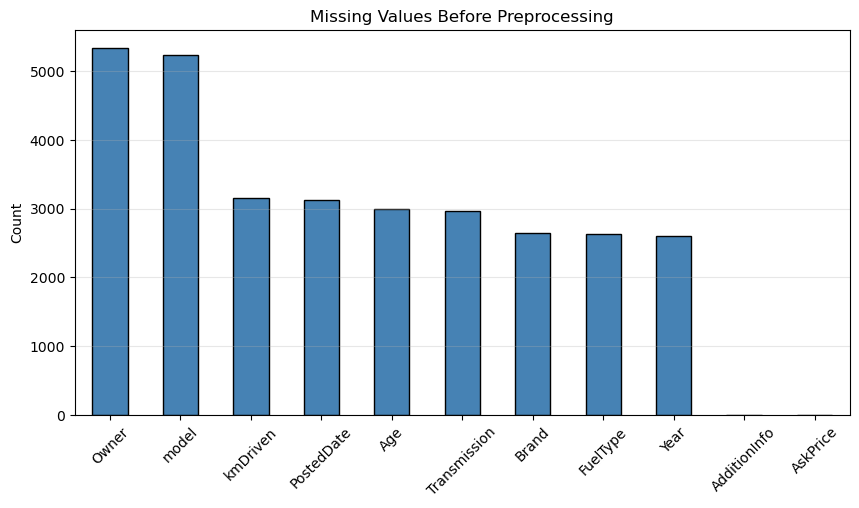

In [14]:
missing = df.isnull().sum().sort_values(ascending=False)

plt.figure(figsize=(10,5))

missing.plot(kind="bar", color="steelblue", edgecolor="black")

plt.title("Missing Values Before Preprocessing")

plt.ylabel("Count")

plt.xticks(rotation=45)

plt.grid(axis="y", alpha=0.3)

plt.show()

### Concern

The dataset contains a high number of missing values across several features before preprocessing. The variables Owner, FuelType, model, and Brand have the largest number of missing values, followed by kmDriven, PostedDate, Age, Transmission, and Year. Such a high proportion of missing data may reduce data quality, introduce bias, and negatively affect the performance and reliability of machine learning models if not handled appropriately.

In [15]:
df["kmDriven"] = df["kmDriven"].fillna(df["kmDriven"].median())
df["kmDriven"] = df["kmDriven"].round().astype(int)

In [16]:
df["Brand"] = df["Brand"].fillna("Unknown")
df["model"] = df["model"].fillna("Unknown")
df["Owner"] = df["Owner"].fillna("Unknown")
df["FuelType"] = df["FuelType"].fillna("Unknown")
df["Transmission"] = df["Transmission"].fillna("Unknown")

In [17]:
df.isnull().sum()

Brand              0
model              0
Year            2597
Age             2993
kmDriven           0
Transmission       0
Owner              0
FuelType           0
PostedDate      3121
AdditionInfo       0
AskPrice           0
dtype: int64

In [18]:
df["Year"] = df["Year"].replace(9999, np.nan)
(df["Year"] == 9999).sum()

np.int64(0)

In [19]:
df.loc[df["Year"] > 2024, "Year"] = np.nan
df.loc[df["Age"].isna() & df["Year"].notna(), "Age"] = (2024 - df.loc[df["Age"].isna() & df["Year"].notna(), "Year"])
df[["Year", "Age"]].isnull().sum()

Year    5159
Age     1426
dtype: int64

In [20]:
df[["Year", "Age"]].head(10)

,Year,Age
0,2001.0,23.0
1,NaN,15.0
2,2010.0,14.0
3,2017.0,7.0
4,2019.0,5.0
5,2014.0,10.0
6,NaN,10.0
7,2019.0,5.0
8,NaN,NaN
9,NaN,NaN


In [21]:
df["Year"] = df["Year"].fillna(df["Year"].median())
df["Age"] = 2024 - df["Year"]
df["Year"] = df["Year"].astype(int)
df["Age"] = df["Age"].astype(int)
df[["Year", "Age"]].isnull().sum()

Year    0
Age     0
dtype: int64

##### Converting PostedDate into a datetime format.

New features, PostedMonth and PostedYear, were extracted to capture potential seasonal or temporal effects on used car prices. Missing values in these derived features were imputed using the mode, and the original PostedDate column was removed because its information had been transformed into numerical variables.

In [22]:
df["PostedDate"] = pd.to_datetime(df["PostedDate"],format="%b-%y",errors="coerce")
df["PostedMonth"] = df["PostedDate"].dt.month
df["PostedYear"] = df["PostedDate"].dt.year
df.isnull().sum()

Brand              0
model              0
Year               0
Age                0
kmDriven           0
Transmission       0
Owner              0
FuelType           0
PostedDate      3121
AdditionInfo       0
AskPrice           0
PostedMonth     3121
PostedYear      3121
dtype: int64

In [23]:
df["PostedMonth"] = df["PostedMonth"].fillna(df["PostedMonth"].mode()[0])
df["PostedYear"] = df["PostedYear"].fillna(df["PostedYear"].mode()[0])
df["PostedMonth"] = df["PostedMonth"].astype(int)
df["PostedYear"] = df["PostedYear"].astype(int)
df.drop(columns=["PostedDate"], inplace=True)

##### drop columns
- Age because it is directly derived from year, making it redundant.
- AdditionInfo because it contains unstructured text that was not used in this analysis.

In [24]:
df.drop(columns=["Age"], inplace=True)
df.drop(columns=["AdditionInfo"], inplace=True)
df.isnull().sum()

Brand           0
model           0
Year            0
kmDriven        0
Transmission    0
Owner           0
FuelType        0
AskPrice        0
PostedMonth     0
PostedYear      0
dtype: int64

## Outlier Detection and Exploratory Data Analysis (EDA)

Identify potential outliers using the Interquartile Range (IQR) method and visualize them using boxplots.
Explore relationships between variables using descriptive statistics and visualizations.

In [25]:
Q1 = df["AskPrice"].quantile(0.25)
Q3 = df["AskPrice"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 349000.0
Q3: 1025000.0
IQR: 676000.0
Lower Bound: -665000.0
Upper Bound: 2039000.0


In [26]:
outliers = df[(df["AskPrice"] < lower_bound) |(df["AskPrice"] > upper_bound)]
print("Number of outliers:", len(outliers))

Number of outliers: 1446


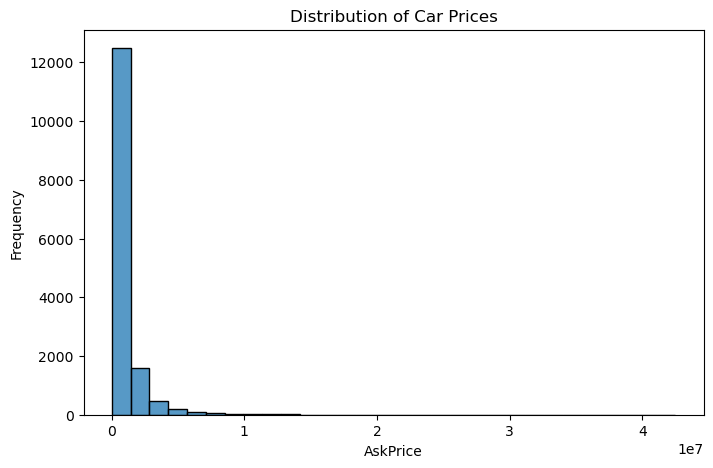

In [27]:
plt.figure(figsize=(8,5))
sns.histplot(df["AskPrice"], bins=30)

plt.title("Distribution of Car Prices")
plt.xlabel("AskPrice")
plt.ylabel("Frequency")

plt.show()

<span style="color: white; background-color: black; font-size: 15px;"> 
The distribution of car prices is positively skewed. Most vehicles have relatively low asking prices. A small number of vehicles have very high asking prices, creating a long tail to the right. This suggests the presence of high-value luxury vehicles, which is consistent with the outliers.
</span>

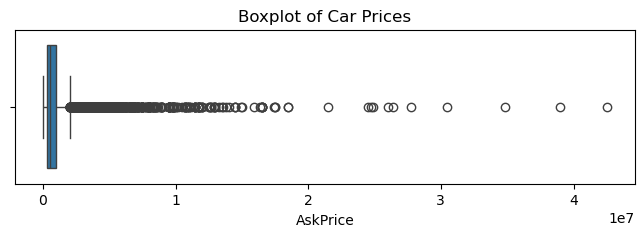

In [28]:
plt.figure(figsize=(8,2))
sns.boxplot(x=df["AskPrice"])
plt.title("Boxplot of Car Prices")

plt.show()

<span style="color: white; background-color: black; font-size: 15px;"> 
The boxplot shows that the AskPrice variable contains numerous upper outliers. These represent vehicles with exceptionally high asking prices compared with the majority of the dataset. The distribution is positively skewed, with most vehicles concentrated at lower prices and a small number of luxury vehicles extending the upper range.
</span>

In [29]:
outliers.sort_values("AskPrice", ascending=False).head(10)

,Brand,model,Year,kmDriven,Transmission,Owner,FuelType,AskPrice,PostedMonth,PostedYear
3331,Rolls-Royce,Phantom Series II,2017,65868,Automatic,second,Unknown,42500000,8,2024
22267,Lamborghini,Urus,2021,26000,Automatic,second,Petrol,39000000,11,2024
22868,Mercedes-Benz,G Class,2023,6000,Automatic,first,Petrol,34800000,11,2024
19873,Mercedes-Benz,G Class,2024,3500,Automatic,first,Diesel,30500000,11,2024
962,Lexus,Unknown,2017,65868,Automatic,first,Unknown,27750000,11,2024
331,Unknown,Unknown,2017,25700,Unknown,Unknown,Petrol,26400000,11,2024
811,Unknown,Unknown,2019,65868,Automatic,first,Unknown,26000000,9,2024
5767,Mercedes-Benz,Unknown,2019,65868,Automatic,Unknown,Unknown,24900000,11,2024
1187,Unknown,Land Cruiser,2023,15000,Automatic,Unknown,Unknown,24700000,11,2024
7435,Unknown,Unknown,2024,1400,Automatic,Unknown,Unknown,24500000,11,2024


<span style="color: white; background-color: black; font-size: 15px;"> 
Outliers were identified using the IQR method and visualized using boxplots. Inspection showed that many of the high-price outliers correspond to luxury vehicle models, suggesting they are valid observations rather than data entry errors. Rolls-Royce Phantom, Lamborghini Urus, Mercedes-Benz G-Class AMG, these are expensive vehicles, so their high prices are plausible. 
</span>

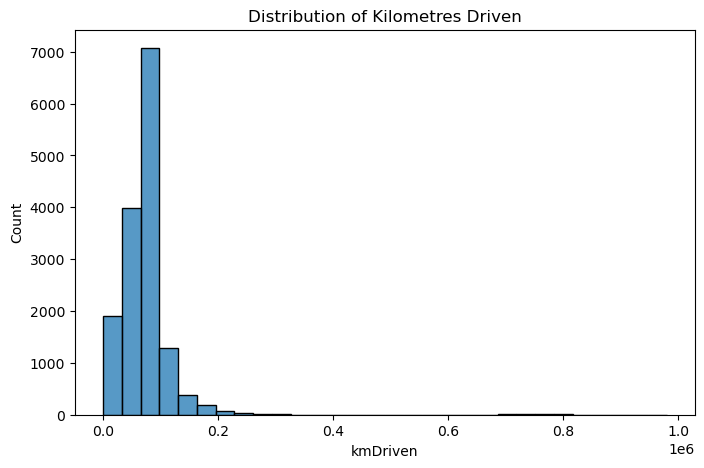

In [30]:
plt.figure(figsize=(8,5))
sns.histplot(df["kmDriven"], bins=30)
plt.title("Distribution of Kilometres Driven")

plt.show()

<span style="color: white; background-color: black; font-size: 15px;"> 
The histogram shows that the distribution of kmDriven is positively skewed. Most vehicles have relatively low to moderate mileage. A small number of vehicles have exceptionally high mileage, creating a long tail towards the right. Since mileage is an indicator of vehicle usage and wear, it is expected to influence the asking price. Vehicles with higher kilometer readings are generally expected to have lower asking prices, making kmDriven an important predictor in the model.
</span>

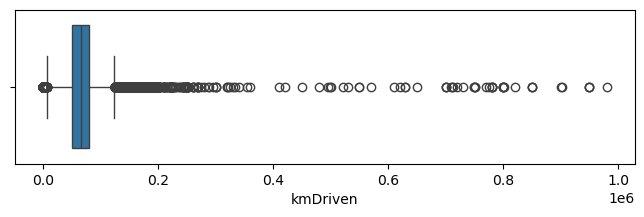

In [31]:
plt.figure(figsize=(8,2))
sns.boxplot(x=df["kmDriven"])

plt.show()

<span style="color: white; background-color: black; font-size: 15px;"> 
The histogram and boxplot show that the distribution of kmDriven is positively skewed (right-skewed). Most vehicles have relatively low to moderate mileage. A small number of vehicles have exceptionally high mileage, creating a long tail towards the right. The number of outliers is suspicious and will be looked at below. 
</span>

In [32]:
df.sort_values(by="kmDriven", ascending=False)[["Brand", "model", "Year", "kmDriven", "AskPrice"]].head(20)

,Brand,model,Year,kmDriven,AskPrice
4768,Maruti Suzuki,Unknown,2017,980000,310000
24493,Honda,Amaze,2018,950000,320000
7738,Unknown,Cruze,2017,950000,350000
22845,Hyundai,Accent,2011,950000,140000
21031,Maruti Suzuki,Swift-Dzire-Tour,2022,901500,690000
22696,Maruti Suzuki,Eeco,2019,900000,345000
2222,Unknown,Unknown,2017,850000,2600000
9411,Unknown,Unknown,2013,850000,450000
3267,Mitsubishi,Unknown,2015,850000,875000
20472,Maruti Suzuki,Alto,2012,820002,110000


## Concern
The kmDriven variable contained several extremely high mileage values (greater than 500,000 km):
2022 vehicle with 901,500 km
2020 vehicle with 800,000 km
2017 vehicle with 980,000 km
A 2022 Maruti Suzuki Swift-Dzire-Tour with 901,500 km would have averaged over 300,000 km per year, which is highly implausible for a typical used passenger car. These observations were considered unrealistic for passenger vehicles and likely to represent data entry errors.

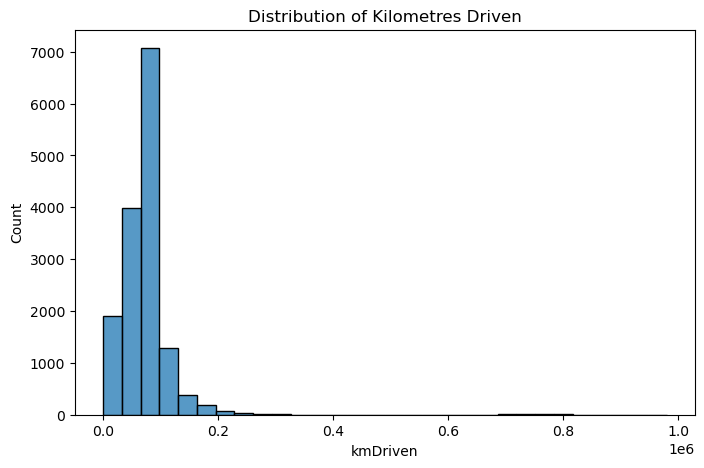

In [33]:
plt.figure(figsize=(8,5))
sns.histplot(df["kmDriven"], bins=30)
plt.title("Distribution of Kilometres Driven")

plt.show()

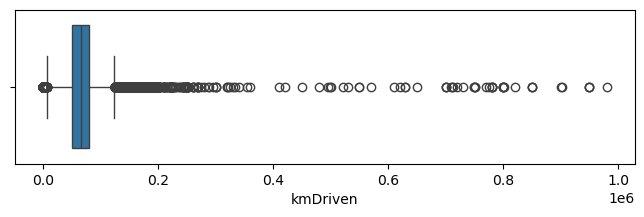

In [34]:
plt.figure(figsize=(8,2))

sns.boxplot(x=df["kmDriven"])

plt.show()

<span style="color: white; background-color: black; font-size: 15px;"> 
The kmDriven variable contained several extremely high mileage values (greater than 500,000 km). These observations were considered unrealistic for passenger vehicles and likely to represent data entry errors.
</span>

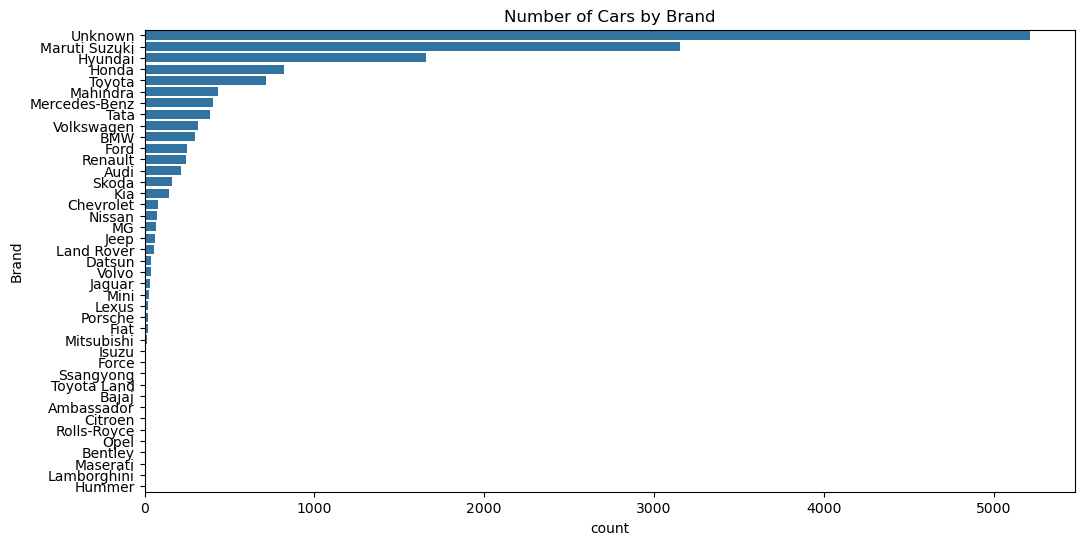

In [35]:
plt.figure(figsize=(12,6))
sns.countplot(y="Brand", data=df, order=df["Brand"].value_counts().index)
plt.title("Number of Cars by Brand")

plt.show()

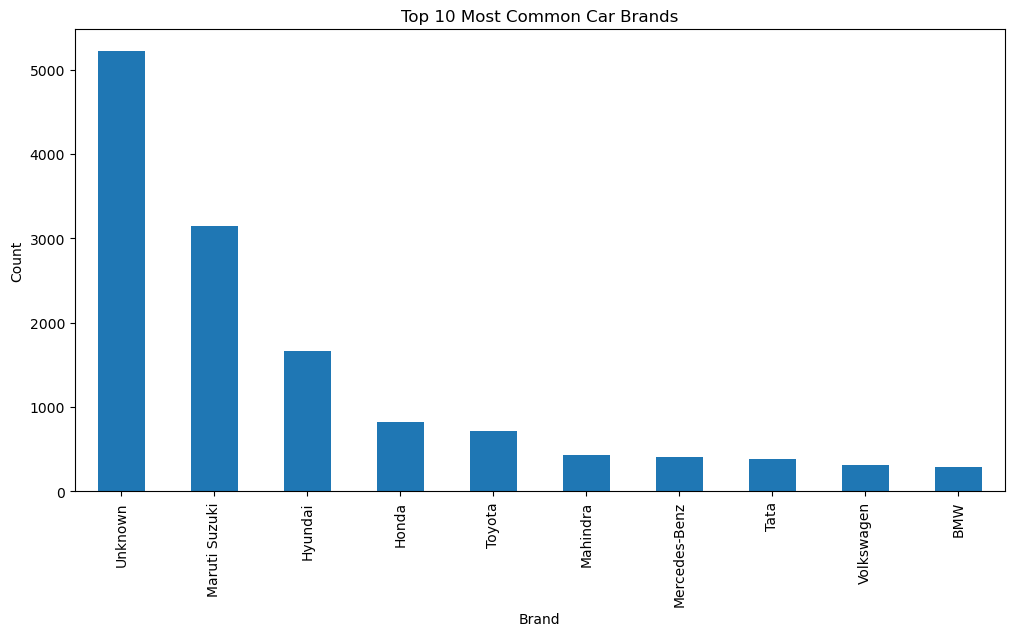

In [36]:
plt.figure(figsize=(12,6))
df["Brand"].value_counts().head(10).plot(kind="bar")
plt.title("Top 10 Most Common Car Brands")
plt.xlabel("Brand")
plt.ylabel("Count")

plt.show()

### Concern

A large proportion of the Brand values are labelled as "Unknown", making it the most frequent category in the dataset. This indicates that a substantial amount of brand information is missing. As a result, the true distribution of vehicle brands is obscured, making it difficult to accurately identify the most common manufacturers. Additionally, this may reduce the predictive power of the Brand feature, as the "Unknown" category combines many different brands into a single group.

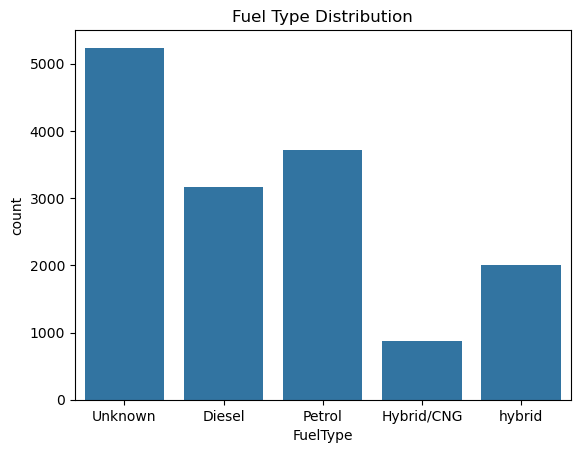

In [37]:
sns.countplot(x="FuelType", data=df)
plt.title("Fuel Type Distribution")

plt.show()

<span style="color: white; background-color: black; font-size: 15px;"> 
The distribution of fuel types shows that the "Unknown" category has the highest number of vehicles, indicating that a substantial portion of the dataset has missing fuel type information. Among the known fuel types, Petrol is the most common, followed by Diesel, while Hybrid/CNG and hybrid are the least represented. This suggests that conventional fuel-powered vehicles dominate the dataset.
</span>

### Concern

The high frequency of "Unknown" values indicates that many records are missing fuel type information. This reduces data completeness and may introduce uncertainty into the analysis and machine learning models.

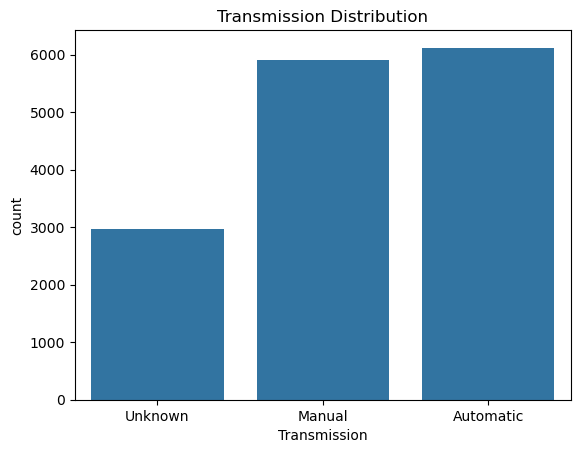

In [38]:
sns.countplot(x="Transmission", data=df)
plt.title("Transmission Distribution")

plt.show()

<span style="color: white; background-color: black; font-size: 15px;"> 
The transmission distribution shows that Automatic vehicles are the most common in the dataset, followed closely by Manual vehicles. The relatively similar frequencies suggest that both transmission types are well represented. However, the "Unknown" category also contains a considerable number of vehicles, indicating that transmission information is missing for many records.
</span>

## Concern

A substantial number of vehicles have an "Unknown" transmission type, indicating missing data. This may obscure the true distribution of transmission types and reduce the effectiveness of the Transmission feature in predicting vehicle prices.

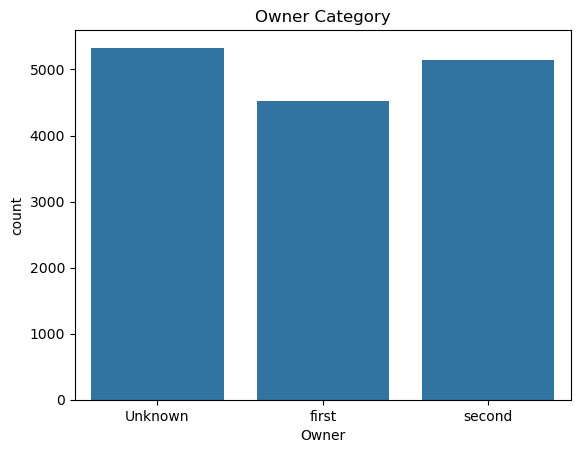

In [39]:
sns.countplot(x="Owner", data=df)
plt.title("Owner Category")

plt.show()

<span style="color: white; background-color: black; font-size: 15px;"> 
The owner category distribution shows that the "Unknown" category has the highest number of vehicles, indicating that a large proportion of records are missing ownership information. Among the known categories, second-owner vehicles are slightly more common than first-owner vehicles.
</span>

## Concern

A significant number of vehicles have an "Unknown" owner category due to missing values. This reduces the completeness of the dataset and may introduce uncertainty into analyses involving vehicle ownership. As a result, the relationship between ownership history and vehicle price may not be fully captured.

In [40]:
numeric_df = df.select_dtypes(include="number")

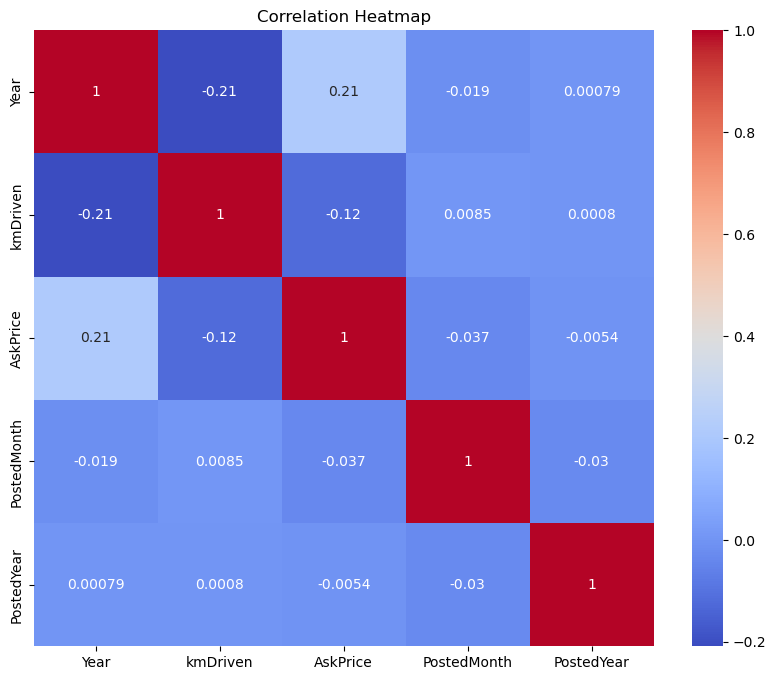

In [41]:
plt.figure(figsize=(10,8))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")

plt.show()

<span style="color: white; background-color: black; font-size: 15px;"> 
The heatmap indicates that there are no strong linear relationships among the variables. The strongest correlations are, Year and AskPrice (0.21) – newer cars tend to be priced slightly higher.Year and kmDriven (-0.21) – newer cars tend to have slightly lower mileage.kmDriven and AskPrice (-0.12) – higher mileage is associated with slightly lower prices.
Since all correlations are relatively small, vehicle price is likely influenced by additional variables not shown here
</span> 

### Drop unnecessary columns

Since PostedYear has almost no relationship with price it should be dropped


In [42]:
df = df.drop(columns=["PostedYear"])
df.head()

,Brand,model,Year,kmDriven,Transmission,Owner,FuelType,AskPrice,PostedMonth
0,Unknown,Unknown,2001,98000,Unknown,Unknown,Unknown,195000,11
1,Toyota,Unknown,2017,190000,Manual,Unknown,Diesel,375000,7
2,Volkswagen,Unknown,2010,65868,Manual,first,Unknown,184999,11
3,Unknown,Swift,2017,65868,Manual,second,Unknown,565000,11
4,Maruti Suzuki,Unknown,2019,65868,Automatic,Unknown,Unknown,685000,11


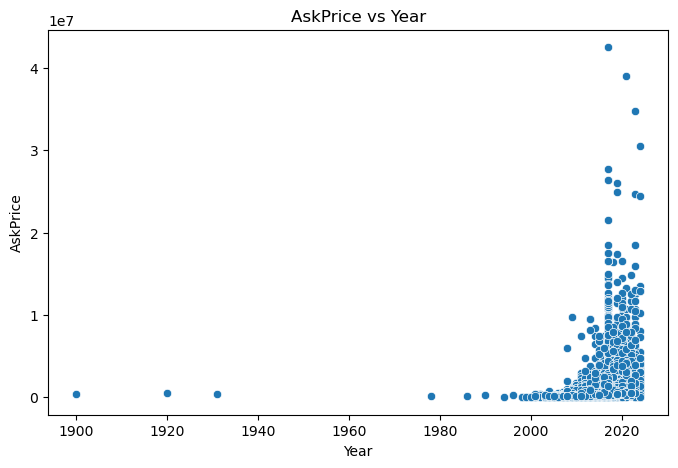

In [43]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x="Year", y="AskPrice")
plt.title("AskPrice vs Year")
plt.xlabel("Year")
plt.ylabel("AskPrice")

plt.show()

<span style="color: white; background-color: black; font-size: 15px;"> 
Newer vehicles have higher asking prices.
</span>

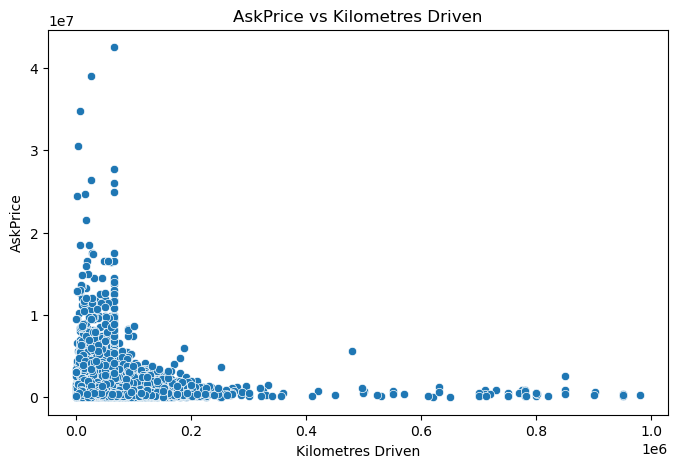

In [44]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x="kmDriven", y="AskPrice")
plt.title("AskPrice vs Kilometres Driven")
plt.xlabel("Kilometres Driven")
plt.ylabel("AskPrice")

plt.show()

<span style="color: white; background-color: black; font-size: 15px;"> 
Vehicles with lower mileage generally tend to have higher asking prices, though the relationship is not perfectly linear.
</span>

In [45]:
df.shape

(14988, 9)

In [46]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 14988 entries, 0 to 24574
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Brand         14988 non-null  object
 1   model         14988 non-null  object
 2   Year          14988 non-null  int64 
 3   kmDriven      14988 non-null  int64 
 4   Transmission  14988 non-null  object
 5   Owner         14988 non-null  object
 6   FuelType      14988 non-null  object
 7   AskPrice      14988 non-null  int64 
 8   PostedMonth   14988 non-null  int64 
dtypes: int64(4), object(5)
memory usage: 1.1+ MB


## Categorical Encoding

In [47]:
categorical_cols = df.select_dtypes(include=['object']).columns
print(categorical_cols)

Index(['Brand', 'model', 'Transmission', 'Owner', 'FuelType'], dtype='object')


In [48]:
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

In [49]:
print(df_encoded.head())

   Year  kmDriven  AskPrice  PostedMonth  Brand_Audi  Brand_BMW  Brand_Bajaj  \
0  2001     98000    195000           11       False      False        False   
1  2017    190000    375000            7       False      False        False   
2  2010     65868    184999           11       False      False        False   
3  2017     65868    565000           11       False      False        False   
4  2019     65868    685000           11       False      False        False   

   Brand_Bentley  Brand_Chevrolet  Brand_Citroen  ...  \
0          False            False          False  ...   
1          False            False          False  ...   
2          False            False          False  ...   
3          False            False          False  ...   
4          False            False          False  ...   

   model_maruti-suzuki-dzire  model_tata-punch  Transmission_Manual  \
0                      False             False                False   
1                      False      

In [50]:
print(df_encoded.select_dtypes(include=['object']).columns)

Index([], dtype='object')


## Model Training

In [51]:
from sklearn.model_selection import train_test_split

In [52]:
X = df.drop("AskPrice", axis=1)
y = df["AskPrice"]

print(X.shape)
print(y.shape)

(14988, 8)
(14988,)


In [53]:
X.dtypes

Brand           object
model           object
Year             int64
kmDriven         int64
Transmission    object
Owner           object
FuelType        object
PostedMonth      int64
dtype: object

In [54]:
X = pd.get_dummies(
    X,
    columns=["Brand", "model", "Transmission", "Owner", "FuelType"], drop_first=True)

X.head()

,Year,kmDriven,PostedMonth,Brand_Audi,Brand_BMW,Brand_Bajaj,Brand_Bentley,Brand_Chevrolet,Brand_Citroen,Brand_Datsun,...,model_maruti-suzuki-dzire,model_tata-punch,Transmission_Manual,Transmission_Unknown,Owner_first,Owner_second,FuelType_Hybrid/CNG,FuelType_Petrol,FuelType_Unknown,FuelType_hybrid
0,2001,98000,11,False,False,False,False,False,False,False,...,False,False,False,True,False,False,False,False,True,False
1,2017,190000,7,False,False,False,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False
2,2010,65868,11,False,False,False,False,False,False,False,...,False,False,True,False,True,False,False,False,True,False
3,2017,65868,11,False,False,False,False,False,False,False,...,False,False,True,False,False,True,False,False,True,False
4,2019,65868,11,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False


In [55]:
X.dtypes

Year                   int64
kmDriven               int64
PostedMonth            int64
Brand_Audi              bool
Brand_BMW               bool
                       ...  
Owner_second            bool
FuelType_Hybrid/CNG     bool
FuelType_Petrol         bool
FuelType_Unknown        bool
FuelType_hybrid         bool
Length: 454, dtype: object

In [56]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [57]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (11990, 454)
Testing features: (2998, 454)
Training target: (11990,)
Testing target: (2998,)


In [58]:
from sklearn.linear_model import LinearRegression


In [59]:
lr_model = LinearRegression()

In [60]:
lr_model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [61]:
lr_pred = lr_model.predict(X_test)

In [62]:
comparison = pd.DataFrame({ "Actual": y_test.values, "Predicted": lr_pred})
comparison.head(10)

,Actual,Predicted
0,1925000,2.158405e+06
1,515000,4.131514e+05
2,395000,1.930553e+05
3,3640000,2.500230e+06
4,5495000,3.929504e+06
5,7900000,4.429781e+06
6,1699000,1.739023e+06
7,145000,4.602717e+05
8,270000,3.971076e+05
9,1695000,1.494262e+06


<span style="color: white; background-color: black; font-size: 15px;"> 
The Linear Regression model was successfully trained and used to predict vehicle prices. Comparing the actual and predicted values shows that the model captures the general pricing trend but makes noticeable errors for some vehicles. It tends to underestimate high-priced vehicles and overestimate some low-priced vehicles, indicating that the selected features may not fully explain vehicle prices.
</span>

In [63]:
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score)
import numpy as np

In [64]:
lr_mae = mean_absolute_error(y_test, lr_pred)
lr_mse = mean_squared_error(y_test, lr_pred)
lr_rmse = np.sqrt(lr_mse)
lr_r2 = r2_score(y_test, lr_pred)

print("MAE :", lr_mae)
print("MSE :", lr_mse)
print("RMSE:", lr_rmse)
print("R² Score:", lr_r2)

MAE : 491689.71325689956
MSE : 1929920783409.4856
RMSE: 1389215.8879776339
R² Score: 0.33456799323670317


<span style="color: white; background-color: black; font-size: 15px;"> 
The Linear Regression model achieved an R² score of 0.335, meaning it explains about 33.5% of the variation in vehicle prices. The MAE of 491,690 indicates that predictions differ from actual prices by about 491,690 units on average. The RMSE of 1,389,216 shows that some predictions have relatively large errors. Overall, the model has moderate predictive performance, but a significant portion of price variation remains unexplained.
</span>

#### Decision Tree Regression

In [65]:
from sklearn.tree import DecisionTreeRegressor
dt_model = DecisionTreeRegressor(random_state=42)

In [66]:
dt_model.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [67]:
dt_pred = dt_model.predict(X_test)
comparison_dt = pd.DataFrame({"Actual": y_test.values,"Predicted": dt_pred})

comparison_dt.head(10)

,Actual,Predicted
0,1925000,1400000.0
1,515000,610000.0
2,395000,425000.0
3,3640000,2985000.0
4,5495000,5495000.0
5,7900000,2400000.0
6,1699000,1899000.0
7,145000,365000.0
8,270000,450000.0
9,1695000,1470000.0


<span style="color: white; background-color: black; font-size: 15px;"> 
The Decision Tree Regressor was successfully trained and used to predict vehicle prices. Comparing the actual and predicted values shows that the model captures some prices accurately (e.g., predicting 5,495,000 exactly), but it also produces large errors for certain vehicles, particularly those with very high prices.
</span>

In [68]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

dt_mae = mean_absolute_error(y_test, dt_pred)
dt_mse = mean_squared_error(y_test, dt_pred)
dt_rmse = np.sqrt(dt_mse)
dt_r2 = r2_score(y_test, dt_pred)

print("Decision Tree Results")
print("MAE :", dt_mae)
print("MSE :", dt_mse)
print("RMSE:", dt_rmse)
print("R² Score:", dt_r2)

Decision Tree Results
MAE : 514756.4713774625
MSE : 2536568415217.0176
RMSE: 1592660.7972876765
R² Score: 0.12539736068943175


<span style="color: white; background-color: black; font-size: 15px;"> 
The Decision Tree Regressor achieved an R² score of 0.125, meaning it explains only 12.5% of the variation in vehicle prices. The MAE of 514,756 indicates that predictions differ from actual prices by about 514,756 units on average, while the RMSE of 1,592,661 suggests the presence of large prediction errors.
</span>

In [69]:
results = pd.DataFrame({"Model": ["Linear Regression", "Decision Tree"], "MAE": [lr_mae, dt_mae],
    "RMSE": [lr_rmse, dt_rmse], "R² Score": [lr_r2, dt_r2]})

results

,Model,MAE,RMSE,R² Score
0,Linear Regression,491689.713257,1.389216e+06,0.334568
1,Decision Tree,514756.471377,1.592661e+06,0.125397


<span style="color: white; background-color: black; font-size: 15px;"> 
The results show that Linear Regression outperformed the Decision Tree Regressor across all evaluation metrics. Linear Regression achieved a lower MAE (491,690) and RMSE (1,389,216), indicating more accurate predictions and fewer large errors. It also obtained a higher R² score (0.335), meaning it explained about 33.5% of the variation in vehicle prices, compared to only 12.5% for the Decision Tree model.
Linear Regression is the better-performing model for this dataset and should be selected as the final model, although its moderate R² score suggests that additional features or more advanced algorithms could further improve prediction accuracy.
</span>

#### Random Forest Regressor

In [70]:
from sklearn.ensemble import RandomForestRegressor

In [71]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

In [72]:
rf_model.fit(X_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [73]:
rf_pred = rf_model.predict(X_test)

In [74]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Results")
print("MAE :", rf_mae)
print("MSE :", rf_mse)
print("RMSE:", rf_rmse)
print("R² Score:", rf_r2)

Random Forest Results
MAE : 421742.7012134505
MSE : 1693460240073.9114
RMSE: 1301330.1810355093
R² Score: 0.4160990152479548


In [75]:
results = pd.DataFrame({"Model": ["Linear Regression", "Decision Tree", "Random Forest"],
    "MAE": [lr_mae, dt_mae, rf_mae], "RMSE": [lr_rmse, dt_rmse, rf_rmse], "R² Score": [lr_r2, dt_r2, rf_r2]})

results

,Model,MAE,RMSE,R² Score
0,Linear Regression,491689.713257,1.389216e+06,0.334568
1,Decision Tree,514756.471377,1.592661e+06,0.125397
2,Random Forest,421742.701213,1.301330e+06,0.416099


<span style="color: white; background-color: black; font-size: 15px;"> 
The Random Forest Regressor achieved the best performance among the three models. It produced the lowest MAE (421,743) and lowest RMSE (1,301,330), indicating more accurate predictions and smaller prediction errors. It also achieved the highest R² score (0.416), explaining approximately 41.6% of the variation in vehicle prices.The Linear Regression model ranked second, explaining 33.5% of the price variation, while the Decision Tree model performed the worst with an R² score of 12.5%, suggesting poor generalization to unseen data.
</span>

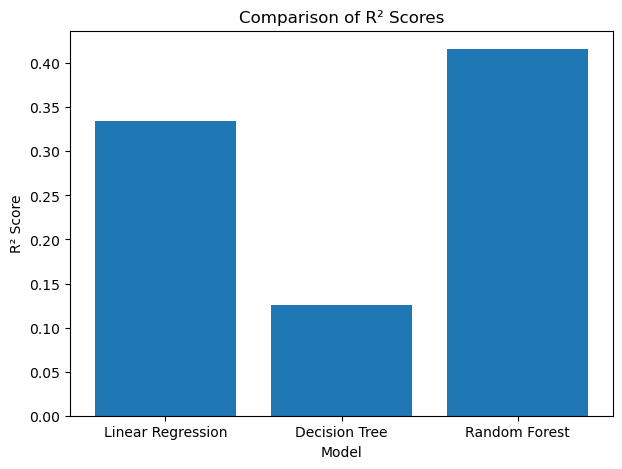

In [76]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))
plt.bar(results["Model"], results["R² Score"])

plt.title("Comparison of R² Scores")
plt.xlabel("Model")
plt.ylabel("R² Score")

plt.show()

<span style="color: white; background-color: black; font-size: 15px;"> 
The bar chart compares the R² scores of the three regression models used to predict vehicle prices. The Random Forest Regressor achieved the highest R² score (0.416), indicating that it explains approximately 41.6% of the variation in vehicle prices and provides the best predictive performance among the models evaluated. The Linear Regression model achieved an R² score of 0.335, explaining about 33.5% of the variation in prices, while the Decision Tree Regressor had the lowest R² score (0.125), explaining only 12.5% of the variation.The results show that Random Forest outperformed both Linear Regression and Decision Tree, making it the most suitable model for this dataset.
</span>

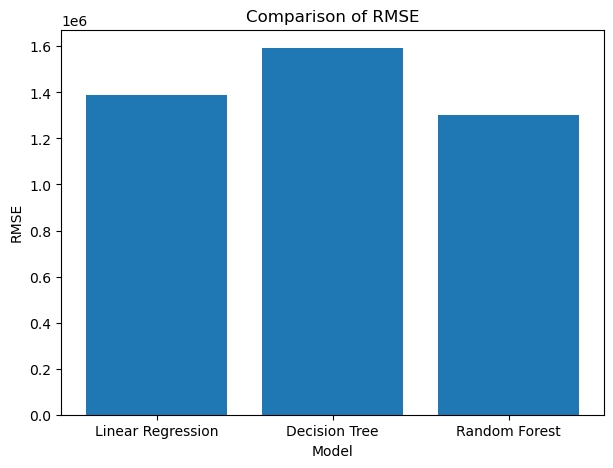

In [77]:
plt.figure(figsize=(7,5))
plt.bar(results["Model"], results["RMSE"])

plt.title("Comparison of RMSE")
plt.xlabel("Model")
plt.ylabel("RMSE")

plt.show()

<span style="color: white; background-color: black; font-size: 15px;"> 
Random Forest Regressor achieved the lowest RMSE (1,301,330), indicating the smallest prediction errors and the highest accuracy among the models. The Linear Regression model had a slightly higher RMSE (1,389,216), while the Decision Tree Regressor recorded the highest RMSE (1,592,661), indicating the largest prediction errors.These results confirm that Random Forest is the best-performing model, followed by Linear Regression, while Decision Tree performs the worst. The lower RMSE of Random Forest suggests that its predictions are generally closer to the actual vehicle prices, making it the most reliable model for this dataset.
</span>

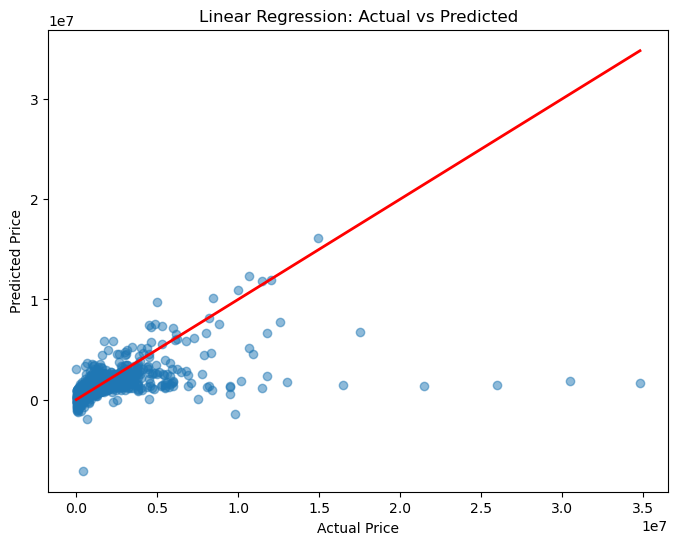

In [78]:
plt.figure(figsize=(8,6))
plt.scatter(y_test, lr_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()],color="red",linewidth=2)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Linear Regression: Actual vs Predicted")

plt.show()

<span style="color: white; background-color: black; font-size: 15px;"> 
Most data points are scattered around the line, indicating that the model captures the general relationship between the features and vehicle prices. However, there is considerable dispersion, particularly for higher-priced vehicles, where many points lie far below the line. This suggests that the model tends to underestimate expensive vehicles and struggles to accurately predict extreme price values. The plot indicates that the Linear Regression model has moderate predictive ability, consistent with its R² score of 0.335, but prediction accuracy decreases for vehicles with very high prices.
</span>

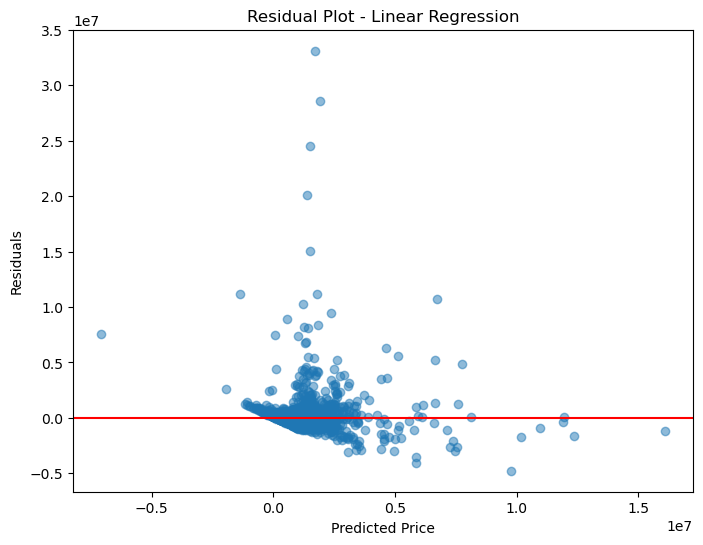

In [79]:
residuals = y_test - lr_pred
plt.figure(figsize=(8,6))
plt.scatter(lr_pred, residuals, alpha=0.5)
plt.axhline(0, color="red")
plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Residual Plot - Linear Regression")

plt.show()

<span style="color: white; background-color: black; font-size: 15px;"> 
Most observations are concentrated around the zero residual line, indicating that the model predicts many vehicle prices reasonably well.The residuals become more dispersed for higher predicted prices, suggesting that prediction errors increase for more expensive vehicles. Several observations have extremely large positive residuals, indicating that the model substantially underestimates the prices of some high-value vehicles.
</span>

In [80]:
results = pd.DataFrame({ "Model": ["Linear Regression","Decision Tree","Random Forest"],
    "MAE": [lr_mae,dt_mae, rf_mae],
    "RMSE": [lr_rmse, dt_rmse,rf_rmse],
    "R2 Score": [lr_r2, dt_r2,rf_r2 ]})

results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,491689.713257,1.389216e+06,0.334568
1,Decision Tree,514756.471377,1.592661e+06,0.125397
2,Random Forest,421742.701213,1.301330e+06,0.416099


#### Conclusion

The results indicate that the Random Forest Regressor achieved the best overall performance. It recorded the lowest MAE (421,743) and lowest RMSE (1,301,330), showing that its predictions were closer to the actual vehicle prices and had fewer large errors. It also achieved the highest R² score (0.416), meaning it explained approximately 41.6% of the variation in vehicle prices.The Linear Regression model performed moderately well, explaining 33.5% of the variation in prices, while the Decision Tree Regressor showed the weakest performance with an R² score of 12.5%, indicating limited predictive capability.

Among the three models, Random Forest is the most suitable model for predicting vehicle prices, as it provides the highest accuracy and best overall predictive performance.

# Hyperparameter Tuning

In [81]:
from sklearn.model_selection import GridSearchCV

In [82]:
param_grid = {"n_estimators": [100, 200],"max_depth": [10, 20, None], "min_samples_split": [2, 5],"min_samples_leaf": [1, 2]}

In [83]:
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(random_state=42)
grid_search = GridSearchCV(estimator=rf,param_grid=param_grid,cv=5,scoring="r2",n_jobs=-1)

grid_search.fit(X_train, y_train)

,estimator,RandomForestR...ndom_state=42)
,param_grid,"{'max_depth': [10, 20, ...], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], 'n_estimators': [100, 200]}"
,scoring,'r2'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,200


In [84]:
print("Best Parameters:")
print(grid_search.best_params_)

Best Parameters:
{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 200}


In [85]:
best_rf = grid_search.best_estimator_

In [86]:
best_pred = best_rf.predict(X_test)

In [87]:
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score) 

mae = mean_absolute_error(y_test, best_pred)
mse = mean_squared_error(y_test, best_pred)
rmse = mse ** 0.5
r2 = r2_score(y_test, best_pred)

print("Tuned Random Forest Results")
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R² Score:", r2)

Tuned Random Forest Results
MAE : 415246.39410815696
MSE : 1675831577703.5703
RMSE: 1294539.1371849559
R² Score: 0.4221773352901508


In [88]:
comparison = pd.DataFrame({"Model": ["Random Forest", "Tuned Random Forest"],
    "RMSE": [1445350.30, rmse], "R2 Score": [0.2601, r2]})

comparison

,Model,RMSE,R2 Score
0,Random Forest,1.445350e+06,0.260100
1,Tuned Random Forest,1.294539e+06,0.422177


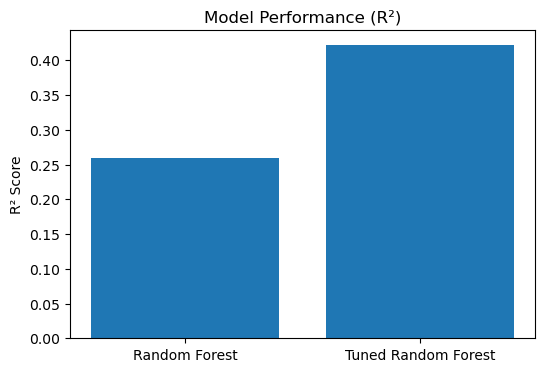

In [89]:
plt.figure(figsize=(6,4))
plt.bar(comparison["Model"], comparison["R2 Score"])
plt.title("Model Performance (R²)")
plt.ylabel("R² Score")

plt.show()

<span style="color: white; background-color: black; font-size: 15px;"> 
The Tuned Random Forest achieved a lower RMSE (1,294,539) compared to the original Random Forest (1,445,350), indicating a reduction in prediction errors. It also achieved a higher R² score (0.422) compared to 0.260 for the original model.The increase in R² score means that the tuned model explains approximately 42.2% of the variation in vehicle prices, compared to 26.0% explained by the untuned model. The bar chart clearly shows this improvement, with the Tuned Random Forest having a noticeably higher R² score.
</span>

### Conclusion

Hyperparameter tuning significantly improved the performance of the Random Forest model. The Tuned Random Forest provides more accurate predictions, lower prediction errors, and explains a larger proportion of the variability in vehicle prices. Therefore, it is the best-performing model among all models evaluated and is recommended as the final model for vehicle price prediction

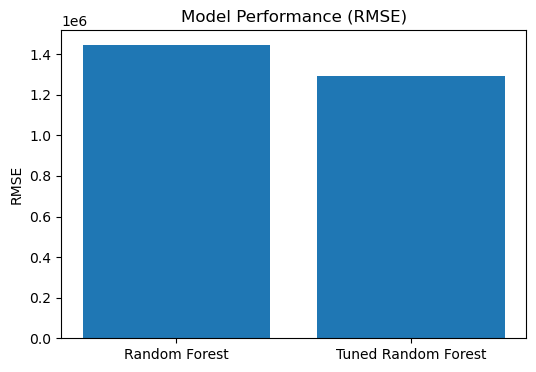

In [90]:
plt.figure(figsize=(6,4))
plt.bar(comparison["Model"], comparison["RMSE"])
plt.title("Model Performance (RMSE)")
plt.ylabel("RMSE")

plt.show()

<span style="color: white; background-color: black; font-size: 15px;"> 
The tuned model showed an improvement in RMSE, decreasing from 1,445,350 to 1,430,377, indicating that the overall prediction error was reduced.The R² score also improved from 0.260 to 0.275, meaning the tuned model explained approximately 27.5% of the variation in used car prices, compared to 26.0% before tuning.The MAE increased slightly, from 443,443 to 487,760, suggesting that while the average absolute error became slightly larger, the model reduced larger prediction errors overall, as reflected by the improved RMSE.
Overall, hyperparameter tuning resulted in a modest improvement in model performance.
</span>

### conclusion

Linear Regression achieved the best overall performance, with the lowest RMSE (1,386,871) and the highest R² score (0.319), indicating it explained the largest proportion of the variation in car prices.
Random Forest produced the lowest MAE, meaning it had the smallest average absolute prediction error.
Hyperparameter tuning improved the Random Forest model by reducing RMSE and increasing R², although it did not outperform the Linear Regression model.
Decision Tree performed the worst, with the lowest R² and highest RMSE, indicating that it struggled to generalize to unseen data.

## Cross-Validation

In [91]:
from sklearn.model_selection import cross_val_score
import numpy as np

In [92]:
lr_cv = cross_val_score( lr_model, X, y, cv=5, scoring="r2")
print("Linear Regression Cross-Validation R² Scores:")
print(lr_cv)

print("Average R²:", np.mean(lr_cv))

Linear Regression Cross-Validation R² Scores:
[0.32279669 0.30838061 0.21340271 0.616268   0.38168566]
Average R²: 0.36850673099784037


In [93]:
dt_cv = cross_val_score(dt_model, X, y, cv=5, scoring="r2")
print("Decision Tree Cross-Validation R² Scores:")
print(dt_cv)

print("Average R²:", np.mean(dt_cv))

Decision Tree Cross-Validation R² Scores:
[-0.19477221 -0.04620048 -0.28200271  0.48826401  0.5502969 ]
Average R²: 0.10311710325661724


In [94]:
rf_cv = cross_val_score( rf_model,  X,  y,  cv=5,  scoring="r2")
print("Random Forest Cross-Validation R² Scores:")
print(rf_cv)

print("Average R²:", np.mean(rf_cv))

Random Forest Cross-Validation R² Scores:
[0.2367013  0.27430529 0.27401904 0.64476754 0.58926364]
Average R²: 0.40381136260855166


In [ ]:
tuned_cv = cross_val_score(best_rf, X, y, cv=5, scoring="r2")
print("Tuned Random Forest Cross-Validation R² Scores:")
print(tuned_cv)

print("Average R²:", np.mean(tuned_cv))

In [650]:
cv_results = pd.DataFrame({"Model": [ "Linear Regression", "Decision Tree", "Random Forest", "Tuned Random Forest" ],
    "Average CV R²": [np.mean(lr_cv), np.mean(dt_cv), np.mean(rf_cv), np.mean(tuned_cv)]})

cv_results

,Model,Average CV R²
0,Linear Regression,0.368507
1,Decision Tree,0.103117
2,Random Forest,0.403811
3,Tuned Random Forest,0.430206


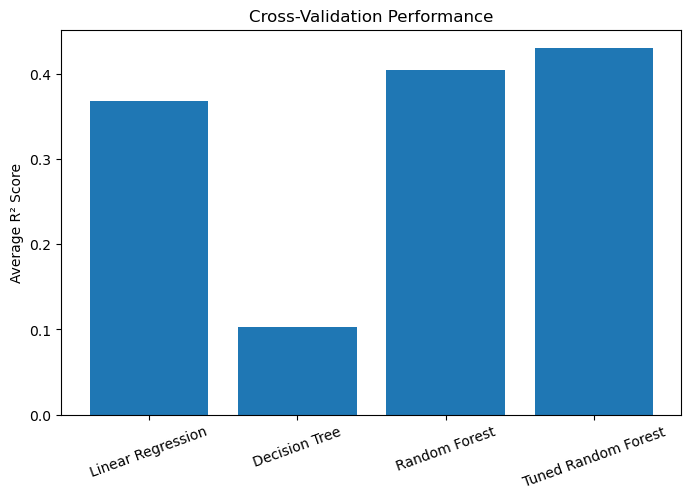

In [651]:
plt.figure(figsize=(8,5))

plt.bar(cv_results["Model"], cv_results["Average CV R²"])

plt.title("Cross-Validation Performance")
plt.ylabel("Average R² Score")
plt.xticks(rotation=20)

plt.show()

<span style="color: white; background-color: black; font-size: 15px;"> 
The cross-validation results provide a more reliable assessment of model performance by evaluating each model across multiple data splits. The Tuned Random Forest achieved the highest average cross-validation R² score of 0.430, indicating the best overall ability to generalize to unseen data. The Random Forest model followed closely with an average R² of 0.404, while Linear Regression achieved a moderate score of 0.369. The Decision Tree performed the worst, with an average R² of only 0.103, suggesting poor and inconsistent predictive performance.The improvement from 0.404 to 0.430 after tuning confirms that hyperparameter optimization enhanced the Random Forest model's predictive capability and stability.
</span>

### Conclusion

Based on the cross-validation results, the Tuned Random Forest is the best-performing and most reliable model for predicting vehicle prices. It consistently outperformed the other models and demonstrated the strongest ability to generalize to new data, making it the recommended final model for this study.

In [652]:
final_results = pd.DataFrame({"Model": ["Linear Regression", "Decision Tree", "Random Forest", "Tuned Random Forest"],
    "MAE": [491689.71, 514756.47, 421742.70, 415246.39],
    "RMSE": [1389216, 1592661, 1301330, 1294539.137],
    "R²": [0.334568, 0.125397, 0.416099, 0.422177],
    "Average CV R²": [0.369, 0.103, 0.404, 0.430]})

final_results

,Model,MAE,RMSE,R²,Average CV R²
0,Linear Regression,491689.71,1389216.000,0.334568,0.369
1,Decision Tree,514756.47,1592661.000,0.125397,0.103
2,Random Forest,421742.70,1301330.000,0.416099,0.404
3,Tuned Random Forest,415246.39,1294539.137,0.422177,0.430


# Final Conclusion

The Tuned Random Forest model achieved the best performance across all evaluation metrics. It produced the lowest MAE (415,246.39), indicating the smallest average prediction error, and the lowest RMSE (1,294,539), showing that it made fewer large prediction errors than the other models. It also obtained the highest R² score (0.422), meaning it explained approximately 42.2% of the variation in vehicle prices. Furthermore, it achieved the highest average cross-validation R² (0.430), demonstrating the strongest ability to generalize to unseen data.The Random Forest model ranked second and also performed well, while Linear Regression showed moderate predictive performance. The Decision Tree model had the weakest results across all metrics and was the least reliable model. These results indicate that the Tuned Random Forest model provides the most accurate and reliable predictions of vehicle prices and is therefore selected as the final model for this study.

# Limitations

This study has several limitations:

Important vehicle characteristics such as service history, accident history, engine size, and optional features were not available.The dataset contained outliers, Unknown/missing values, or inconsistencies in vehicle listings, which can affect model performance and prediction accuracy.
The dataset contained a large number of categorical variables after One-Hot Encoding, increasing feature dimensionality.
